# Compute UMAPs outside of model training pipeline

Extract the key UMAP functions from the OOP framework so that I can compute for any data.

In [ ]:
from os.path import join
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import torch
import polars as pl

from cytoself.analysis.analysis_opencell import AnalysisOpenCell
from cytoself.datamanager.opencell import DataManagerOpenCell
from cytoself.trainer.cytoselflite_trainer import CytoselfFullTrainer
from cytoself.trainer.utils.plot_history import plot_history_cytoself
from cytoself.analysis.utils.cluster_score import calculate_cluster_centrosize

In [6]:
datapath = '../model_inputs/2024_01_Batch_7-8'
outputpath = "../trained_models/varchamp_v2"
model_nm = "model_30.pt"
data_ch = ['pro', 'nuc']
device="cuda:0"
model_path = f"{outputpath}/{model_nm}"

In [7]:
datamanager = DataManagerOpenCell(datapath, data_ch, fov_col=None)
datamanager.const_dataloader(batch_size=64, label_name_position=1)

Loading pro data...


100%|██████████| 875/875 [02:19<00:00,  6.29it/s]


Loading nuc data...


100%|██████████| 875/875 [02:15<00:00,  6.45it/s]


Loading label data...


100%|██████████| 875/875 [00:00<00:00, 6868.02it/s]


Splitting data...
Computing variance of training data...
Computing variance of validation data...
Computing variance of test data...


In [8]:
model_args = {
    "input_shape": (2, 100, 100),
    "emb_shapes": ((25, 25), (4, 4)),
    "output_shape": (2, 100, 100),
    "fc_output_idx": [2],
    "vq_args": {"num_embeddings": 512, "embedding_dim": 64},
    "num_class": len(datamanager.unique_labels),
    "fc_input_type": "vqvec",
}

train_args = {
    "lr": 0.0004,
    "max_epoch": 100,
    "reducelr_patience": 4,
    "reducelr_increment": 0.1,
    "earlystop_patience": 12,
}

In [9]:
trainer = CytoselfFullTrainer(train_args, homepath=outputpath, model_args=model_args)

# modified ../cytoself/trainer/basetrainer.py due to the following error:
# File ~/igvf/varchamp/2025_laval_submitted/2_individual_assay_results/imaging/2_analysis/3_cytoself/cytoself/trainer/basetrainer.py:550, in BaseTrainer.load_model(self, path, by_weights)
#     537 def load_model(self, path: str, by_weights: bool = True) -> None:
#     538     """
#     539     Load a pytorch model
#     540 
#    (...)
#     548 
#     549     """
# --> 550     _model = torch.load(path)
# UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
# 	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
# `weights_only = False` added.

trainer.load_model(model_path)

A model has been loaded from ../trained_models/varchamp_v2/model_30.pt


In [10]:
## infer embeddings
test_embeddings = trainer.infer_embeddings(datamanager.test_loader)

if isinstance(test_embeddings, tuple) and len(test_embeddings) > 1:
    test_embeddings = test_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
np.save(join(savepath_embeddings, 'embeddings_testdata.npy'), test_embeddings)

Infer: 100%|██████████| 1037/1037 [00:18<00:00, 56.26it/s]


In [11]:
# infer embeddings for training data 
train_embeddings = trainer.infer_embeddings(datamanager.train_loader)
if isinstance(train_embeddings, tuple) and len(train_embeddings) > 1:
    train_embeddings = train_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
np.save(join(savepath_embeddings, 'embeddings_traindata.npy'), train_embeddings)

Infer: 100%|██████████| 10367/10367 [05:06<00:00, 33.82it/s]


In [12]:
# save labels by data
train_labels = datamanager.train_loader.dataset.label
np.save(join(savepath_embeddings, 'labels_traindata.npy'), train_labels)

test_labels = datamanager.test_loader.dataset.label
np.save(join(savepath_embeddings, 'labels_testdata.npy'), test_labels)

In [13]:
import umap.umap_ as umap
import matplotlib.colors as mcolors
import matplotlib

n_neighbors=15
min_dist=0.1
metric='euclidean'
verbose=True

reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist, metric=metric, verbose=verbose)
umap_data = reducer.fit_transform(test_embeddings.reshape(test_embeddings.shape[0], -1))

UMAP( verbose=True)
Wed Apr  9 20:47:53 2025 Construct fuzzy simplicial set
Wed Apr  9 20:47:53 2025 Finding Nearest Neighbors
Wed Apr  9 20:47:53 2025 Building RP forest with 18 trees
Wed Apr  9 20:47:58 2025 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	 4  /  16
	Stopping threshold met -- exiting after 4 iterations
Wed Apr  9 20:48:16 2025 Finished Nearest Neighbor Search
Wed Apr  9 20:48:19 2025 Construct embedding


Epochs completed: 100%| ██████████ 200/200 [00:14]


Wed Apr  9 20:48:37 2025 Finished embedding


In [14]:
labels = datamanager.test_loader.dataset.label
umap_df = pl.DataFrame({
    "Metadata_Protein": list(labels[:, 0]),
    "Metadata_CellID": list(labels[:, 1]),
    "Comp1": umap_data[:, 0],
    "Comp2": umap_data[:, 1]
})
umap_df.write_parquet("../trained_models/varchamp_v2/analysis/umap_data/umap_comps_testdata.parquet")

In [15]:
def get_custom_colormap(num_colors, first_color='#D3D3D3'):
    # Generate a colormap with the specified number of colors
    cmap = plt.get_cmap('tab10', num_colors)
    colors = [mcolors.rgb2hex(cmap(i)) for i in range(num_colors)]
    # Replace the first color with light grey
    colors[0] = first_color
    return colors

In [16]:
gene = "LDHB"
umap_df = umap_df.with_columns(
    pl.when(pl.col("Metadata_Protein").str.contains(gene))
    .then(pl.col("Metadata_Protein"))
    .otherwise(pl.lit("000")).alias("Variant")
).sort("Variant")
num_colors = len(umap_df.select("Variant").to_series().unique().to_list())
cmap = get_custom_colormap(num_colors)

## Just plot UMAPs

In [17]:
import polars as pl
import matplotlib.colors as mcolors
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
umap_df = pl.read_parquet("../trained_models/varchamp_v2/analysis/umap_data/umap_comps_testdata.parquet")

In [19]:
# Compute centroid of each WT
wt_centroid = umap_df.filter(~pl.col("Metadata_Protein").str.contains("-")).group_by("Metadata_Protein").agg([
    pl.col("Comp1").median().alias("Comp1"),
    pl.col("Comp2").median().alias("Comp2"),
])

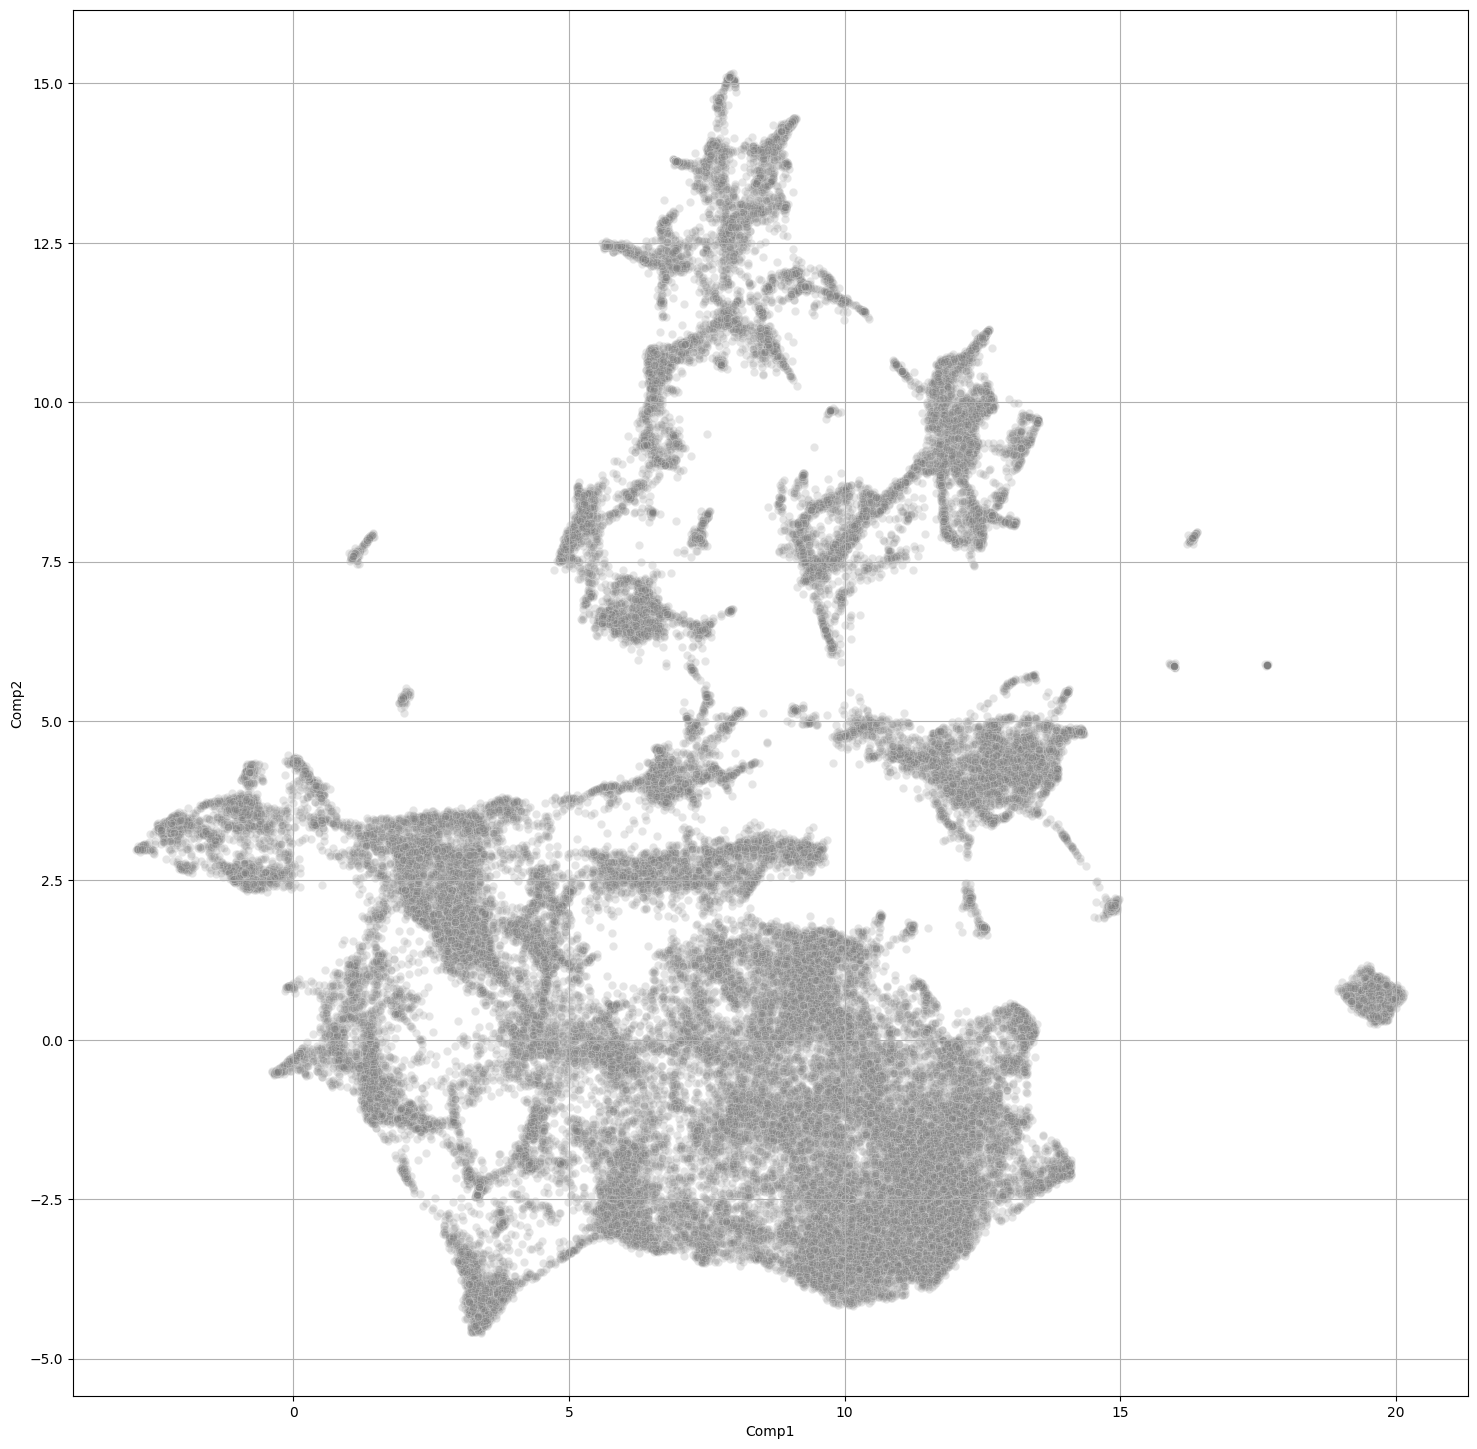

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
sns.scatterplot(umap_df, x="Comp1", y="Comp2", color="grey", alpha=.2, ax=ax)
ax.grid(True)

2025-04-09 20:49:22,540 - WARNING - Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


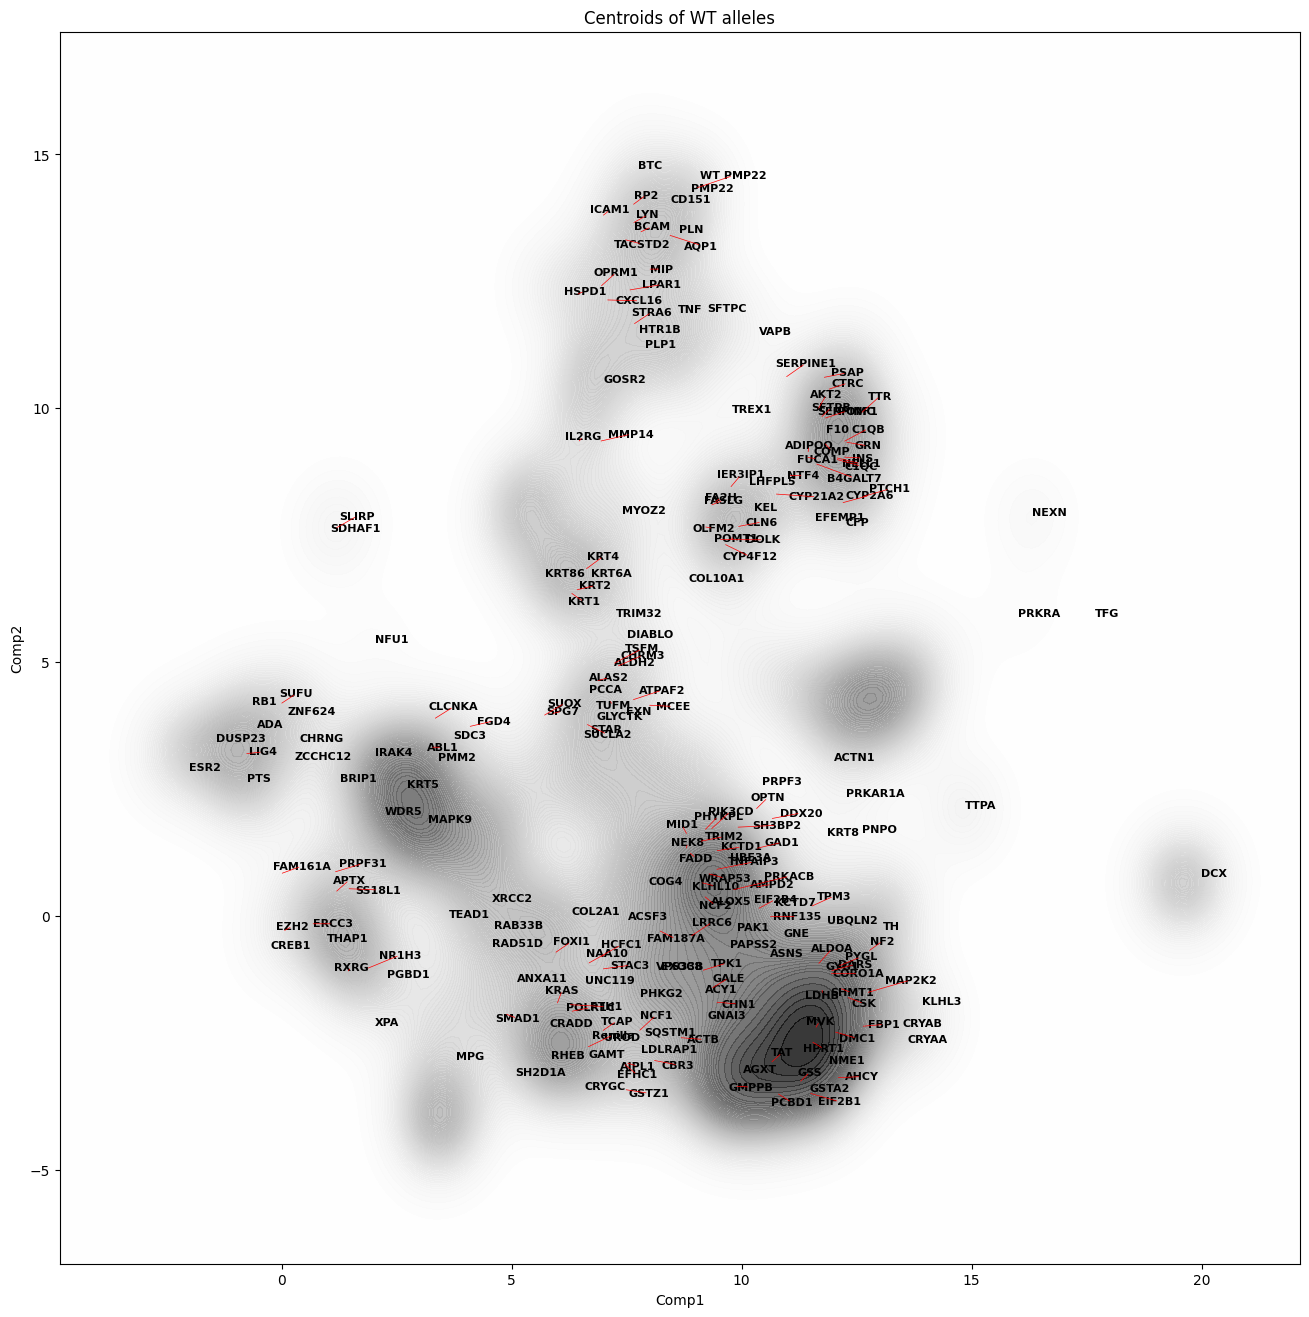

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from adjustText import adjust_text

plt.figure(figsize=(16, 16))
sns.kdeplot(data=umap_df.to_pandas(), x="Comp1", y="Comp2", fill=True, cmap="Greys", alpha=0.8, thresh=0, levels=100)

# Overlay the text labels
texts = []
for i, row in wt_centroid.to_pandas().iterrows():
    texts.append(plt.text(row["Comp1"], row["Comp2"], row["Metadata_Protein"], 
                          fontsize=8, fontweight='bold', color='black'))

# Adjust text to avoid overlaps
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5))
plt.title("Centroids of WT alleles")
plt.savefig("../trained_models/varchamp_v2/analysis/umap_figures/umap_wt_centroid_density.svg", format='svg')

In [22]:
prot_count = umap_df.group_by("Metadata_Protein").agg(pl.count().alias("Frequency"))
prot_count

Metadata_Protein,Frequency
str,u32
"""MYOZ2""",94
"""STXBP1-Arg406H…",38
"""NFU1""",47
"""MLH1-Ala29Gly""",48
"""UROD""",52
"""SMAD3-Leu219Ph…",44
"""KCNJ2-Val302Me…",33
"""MVK-Pro200Ser""",97
"""ACSF3-Gly225Ar…",45


Cool, illustrative examples:
- RP2: clear mislocalization of one variant. It obviously separates from the rest.
- MYOZ2: 3 variants, >80% all piled on top of each other on one very small dot.
- LDHB: 1 variant clearly different

In [23]:
def plot_gene_umap(umap_df, gene):
    fig, ax = plt.subplots(1, 1, figsize=(18, 18))
    ax.grid(True)

    umap_df = umap_df.with_columns(
        pl.when(pl.col("Metadata_Protein").str.contains(gene))
        .then(pl.col("Metadata_Protein"))
        .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
    ).sort(f"{gene}_Variant")
    
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") == "000"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") != "000"), x="Comp1", y="Comp2", hue=f"{gene}_Variant", palette="Set1", ax=ax, s=70, alpha=0.7)

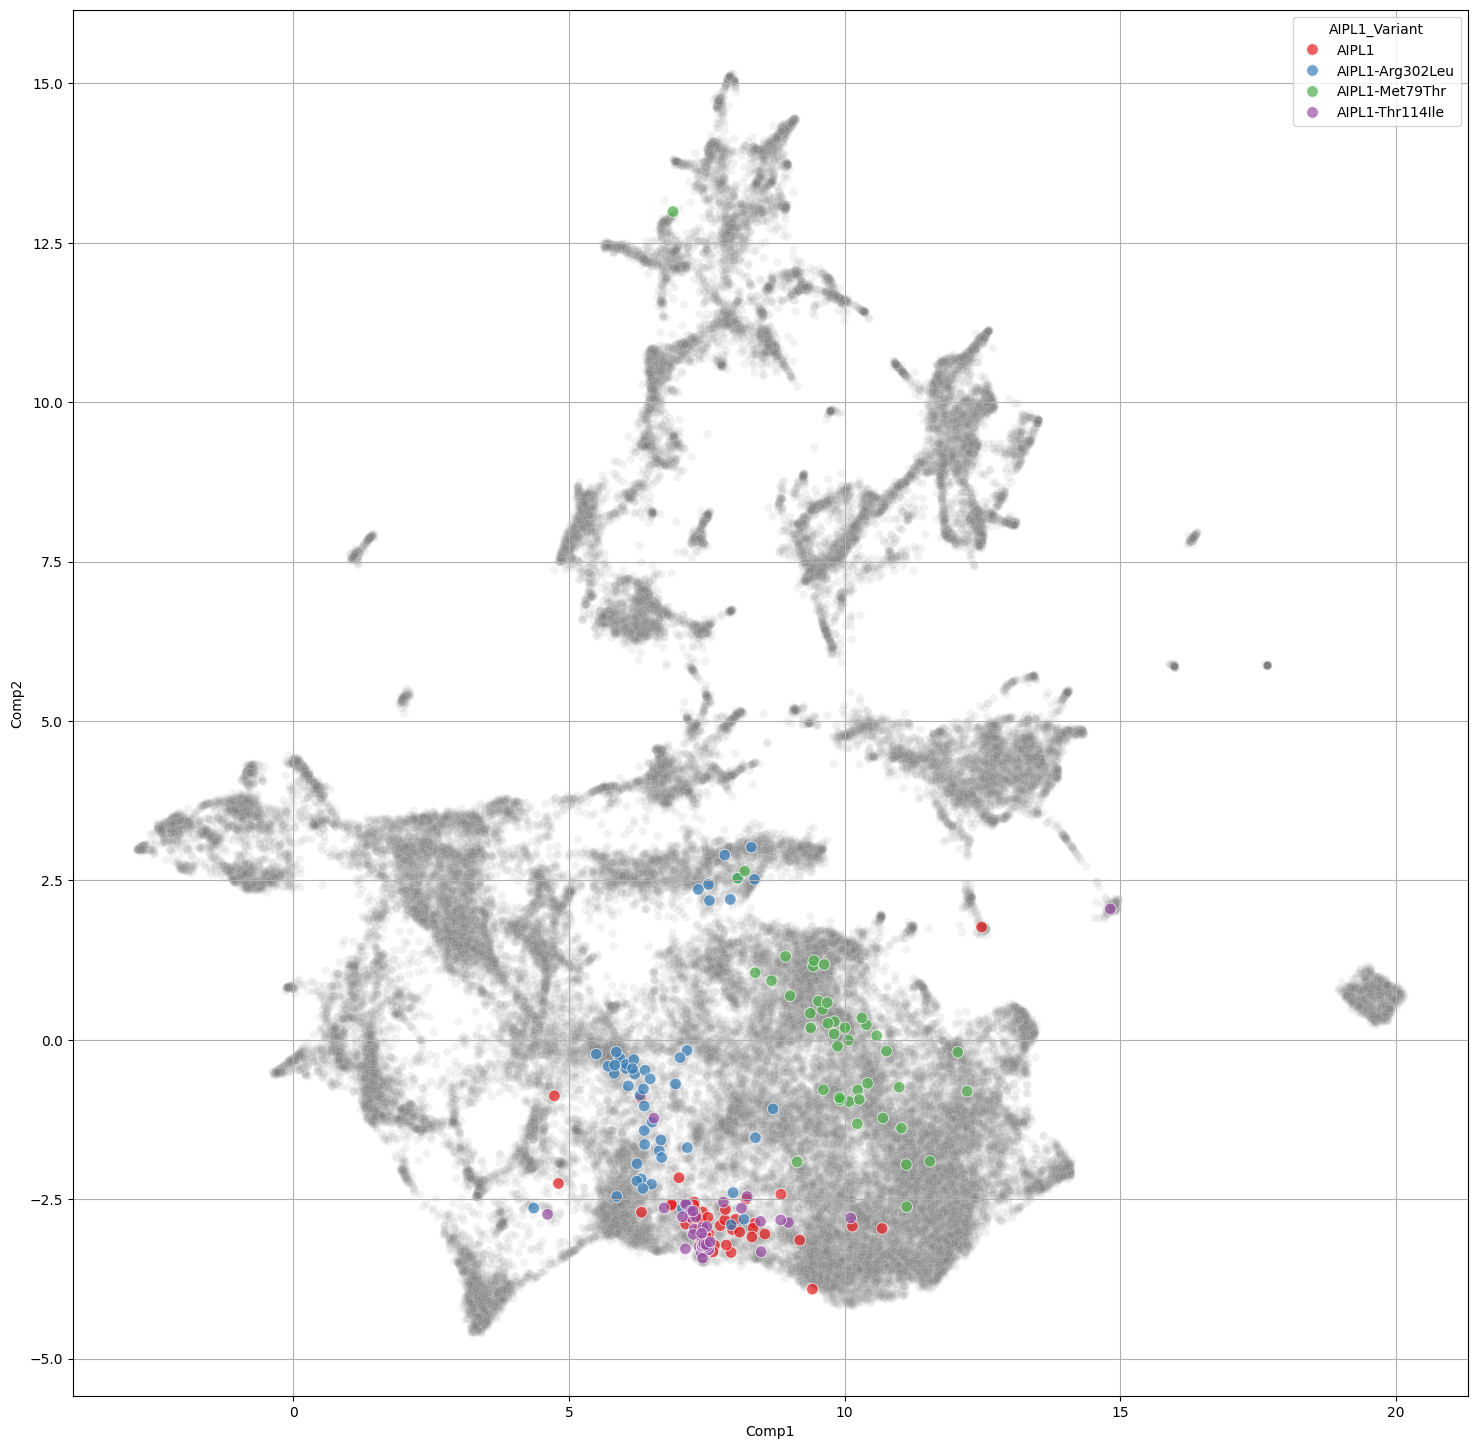

In [24]:
plot_gene_umap(umap_df, "AIPL1")

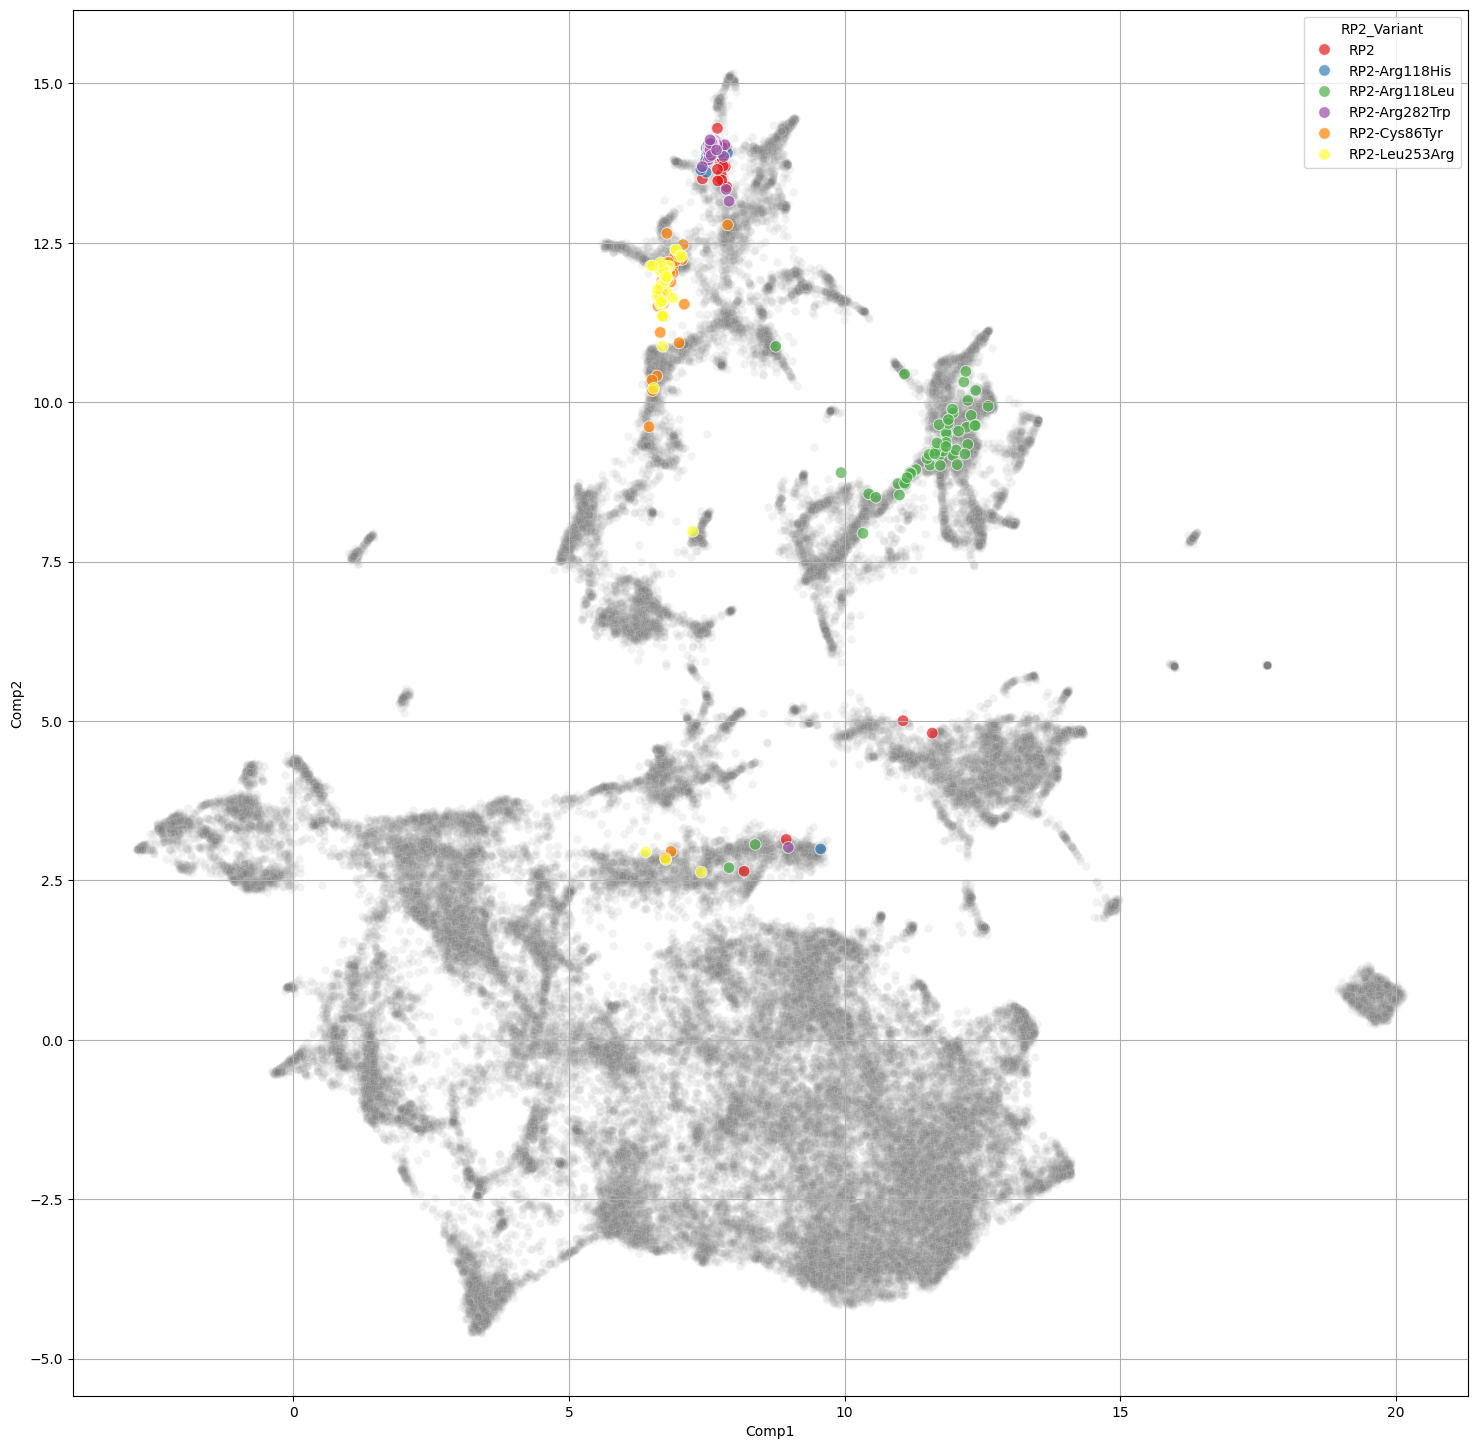

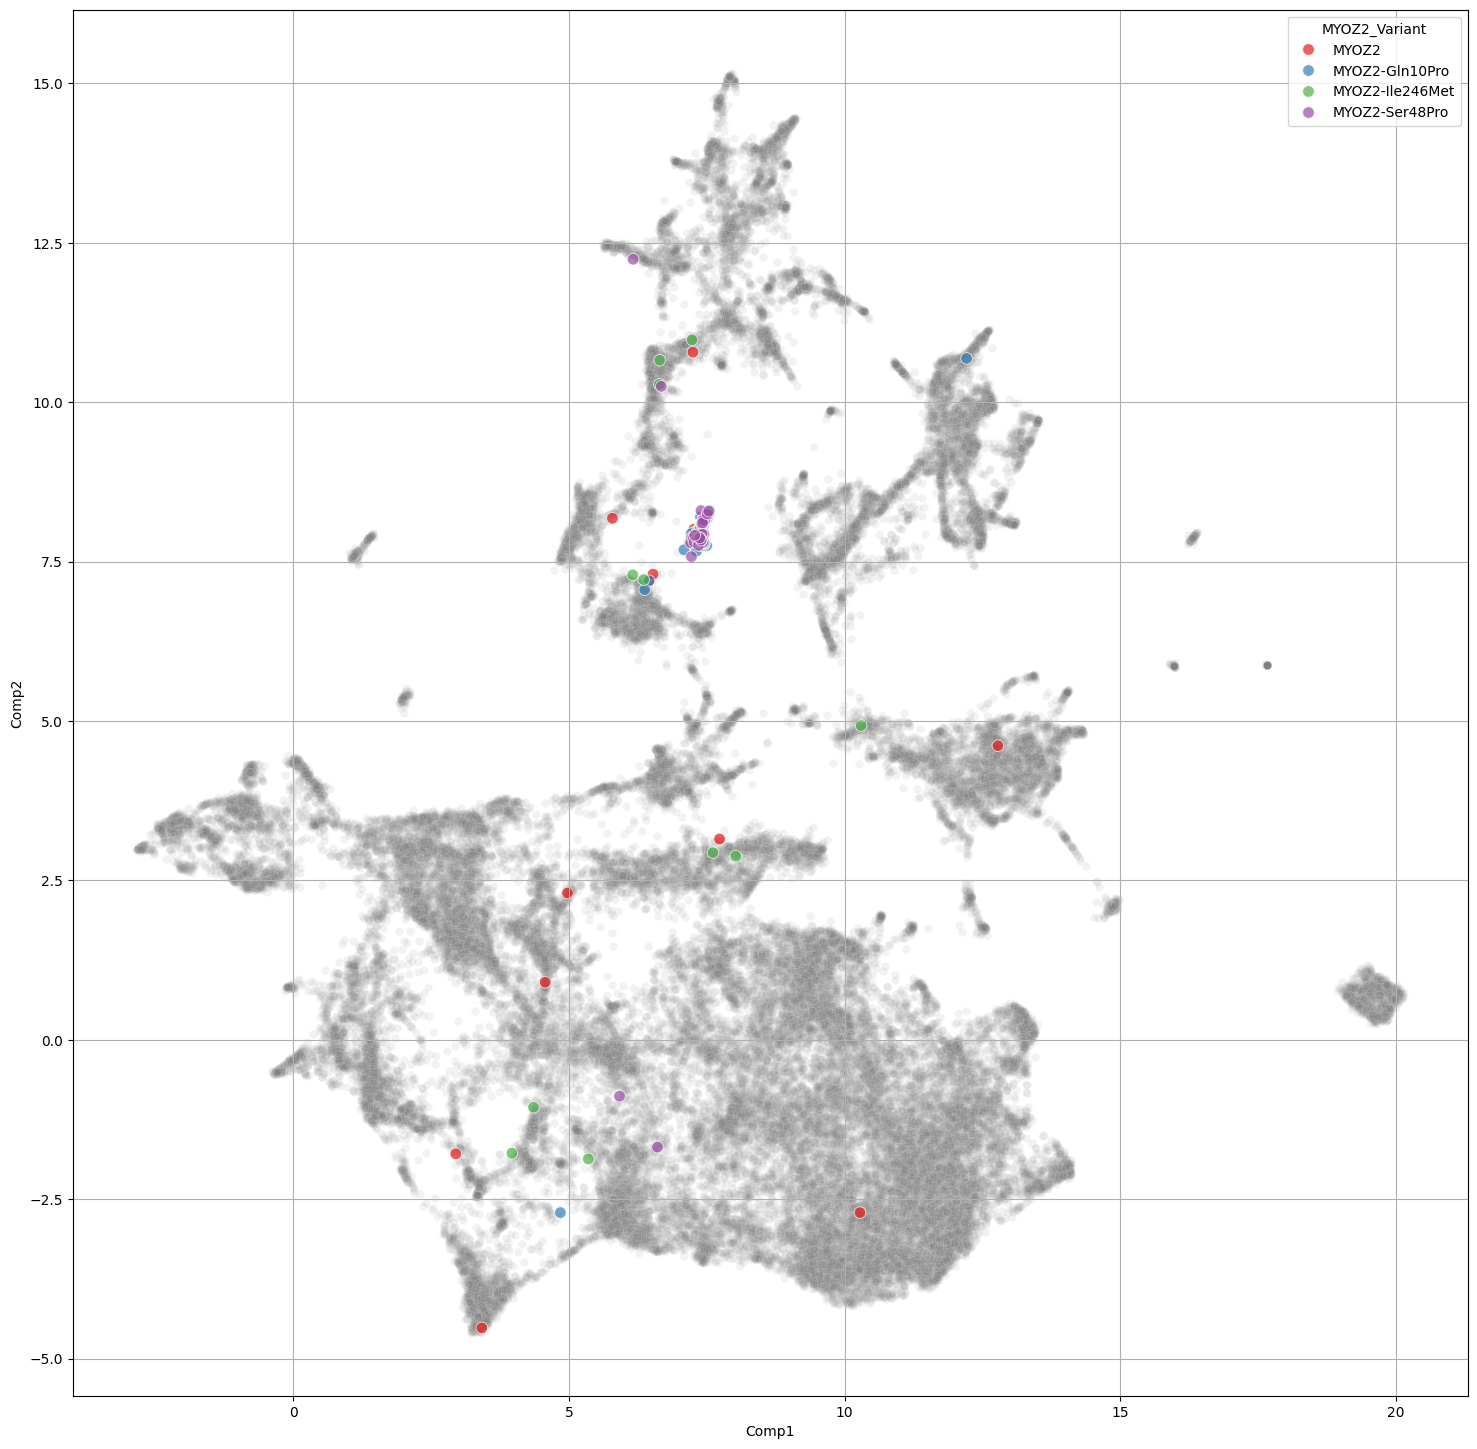

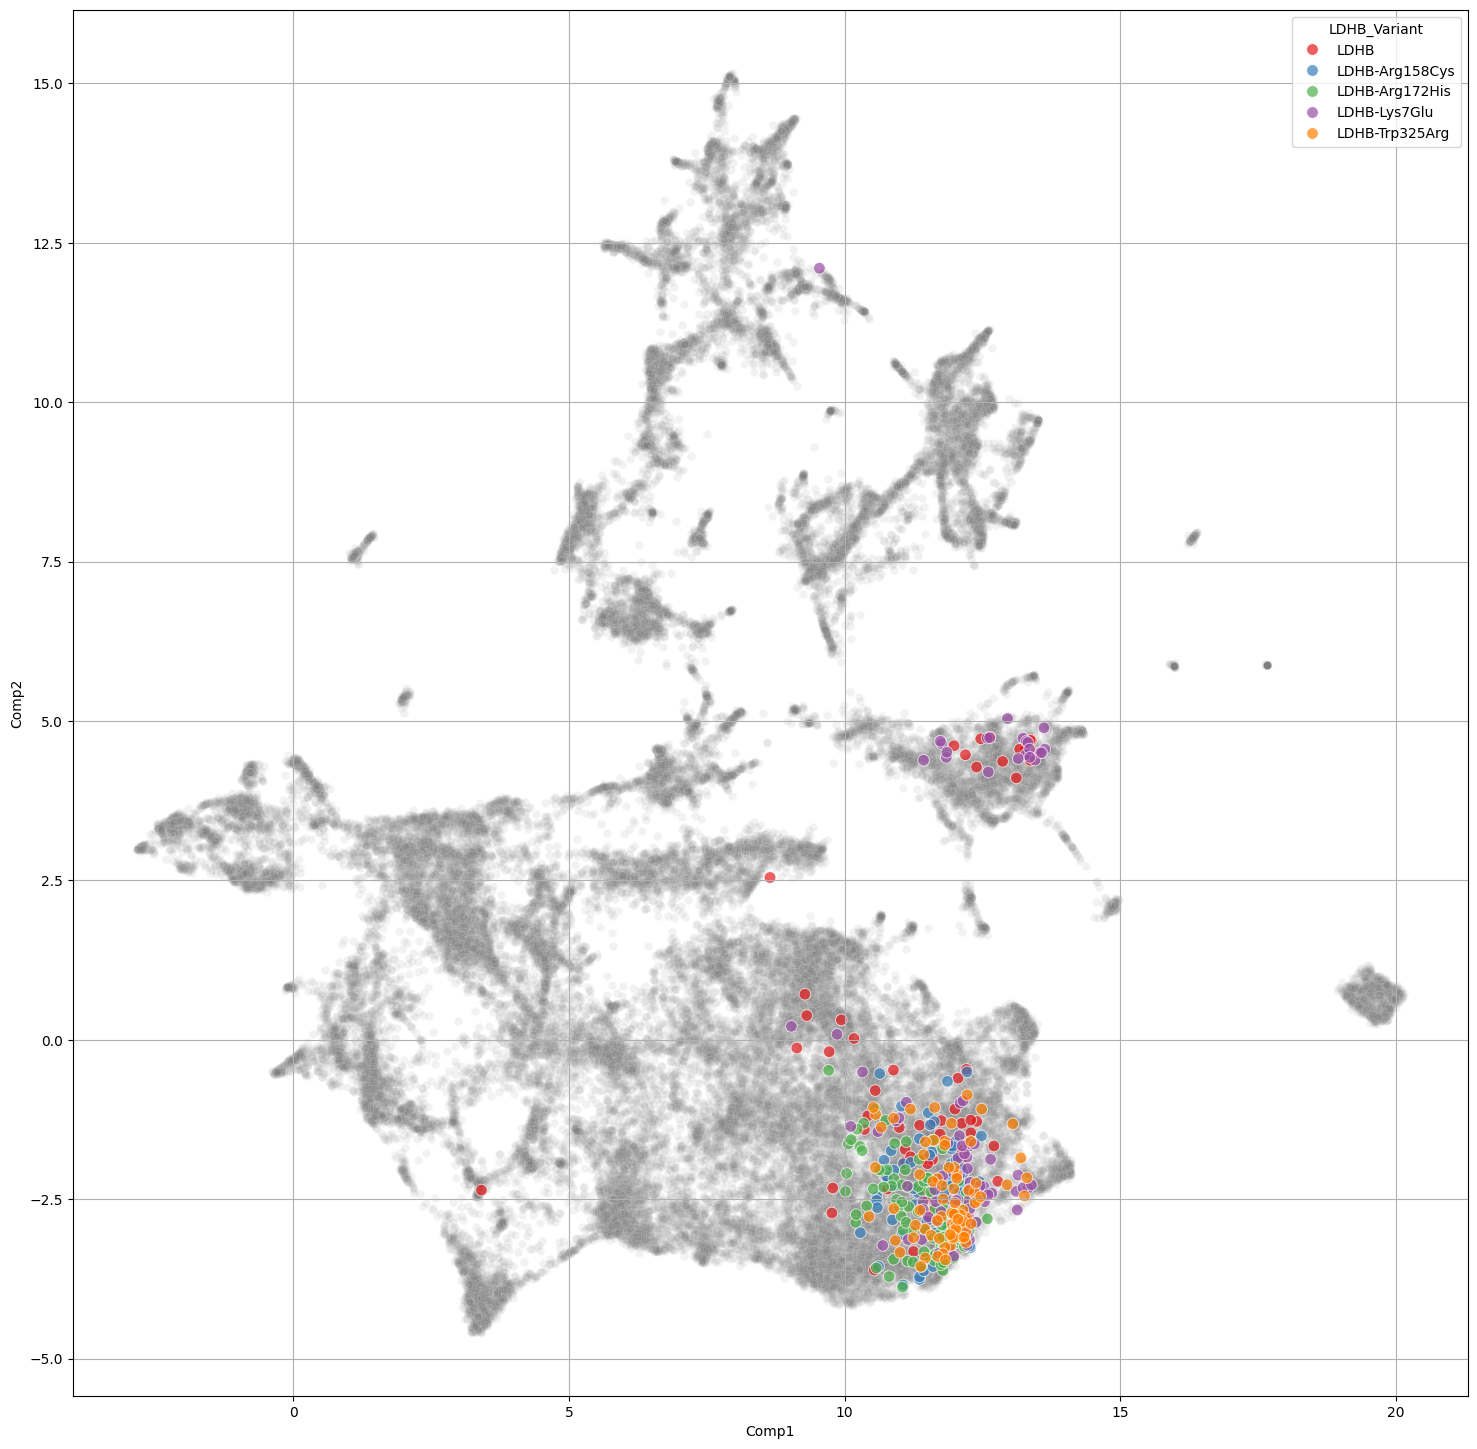

In [25]:
plot_gene_umap(umap_df, "RP2")
plot_gene_umap(umap_df, "MYOZ2")
plot_gene_umap(umap_df, "LDHB")

Next steps:
- Reproduce their cluster analysis with GO:CC and Corum complexes. Try implement the idea that I had for spatial enrichment. 
- Adapt pooled-rare plotting functions for the Varchamp data so that I can look up specific cells based on the UMAP location.
- Make comparable UMAPs with CellProfiler features: use all same QA/QC filters, plus downsample to ~10%